# SO SÁNH VÀ ĐÁNH GIÁ CÁC MÔ HÌNH NHẬN DIỆN TIỀN GIẤY

**Đề tài:** So sánh các mô hình CustomCNN, MobileNetV2, Random Forest, ResNet và YOLO  
**Nguồn dữ liệu:** Các file CSV, TXT và biểu đồ đã được xuất trong thư mục `ket_qua_thong_ke/`.

## Mục tiêu

1. Khám phá cấu trúc dữ liệu thống kê của từng mô hình.
2. Tổng hợp số lượng dự đoán, nhãn loại tiền, mệnh giá, trạng thái và độ tin cậy khi dữ liệu cho phép.
3. Trực quan hóa và so sánh kết quả giữa các mô hình.
4. Đánh giá ưu điểm, hạn chế và khả năng ứng dụng.
5. Chỉ tính Accuracy, Precision, Recall, F1-score khi có nhãn thực tế tương ứng. **Độ tin cậy (confidence) không đồng nghĩa với độ chính xác (accuracy).**

> Notebook không huấn luyện lại mô hình. Notebook đọc các kết quả đã được tạo sẵn trong `ket_qua_thong_ke/`.

## 1. Chuẩn bị môi trường và đường dẫn dữ liệu

Đặt notebook `DH23TIN07_Nhom_05.ipynb` tại thư mục gốc dự án, cùng cấp với `ket_qua_thong_ke/`.

Cấu trúc thư mục dự kiến:

```text
Project/
├── DH23TIN07_Nhom_05.ipynb
└── ket_qua_thong_ke/
    ├── CustomCNN/
    ├── MobilenetV2/
    ├── Random_Forest/
    ├── ResNet/
    ├── RestNet/
    └── YoLo/
```

Nếu notebook được đặt ở vị trí khác, hãy sửa biến `RESULT_DIR` trong cell tiếp theo.

In [2]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

# Thư mục chứa notebook
BASE_DIR = Path.cwd()

# Nếu cần, thay bằng đường dẫn tuyệt đối, ví dụ:
# RESULT_DIR = Path(r"D:\Python-Final-Project\ket_qua_thong_ke")
RESULT_DIR = BASE_DIR / "ket_qua_thong_ke"

MODEL_FOLDERS = {
    "CustomCNN": ["CustomCNN"],
    "MobileNetV2": ["MobilenetV2", "MobileNetV2"],
    "Random Forest": ["Random_Forest", "Random Forest"],
    "ResNet": ["ResNet"],
    "YOLO": ["YoLo", "YOLO"]
}

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Thư mục hiện tại:", BASE_DIR)
print("Thư mục kết quả:", RESULT_DIR)
print("Tồn tại:", RESULT_DIR.exists())

Thư mục hiện tại: c:\Users\ADmin\Desktop\Python-Final-Project
Thư mục kết quả: c:\Users\ADmin\Desktop\Python-Final-Project\ket_qua_thong_ke
Tồn tại: True


## 2. Khám phá cấu trúc thư mục kết quả

Cell dưới đây tìm các thư mục mô hình, liệt kê file CSV, TXT và PNG. `RestNet` được xem là thư mục riêng cần kiểm tra; không tự động gộp với `ResNet` để tránh thống kê trùng.

In [4]:
def resolve_model_folder(folder_candidates):
    for folder_name in folder_candidates:
        candidate = RESULT_DIR / folder_name
        if candidate.exists() and candidate.is_dir():
            return candidate
    return None

model_paths = {
    model: resolve_model_folder(candidates)
    for model, candidates in MODEL_FOLDERS.items()
}

structure_rows = []
for model, folder in model_paths.items():
    if folder is None:
        structure_rows.append({
            "Mô hình": model, "Thư mục": ", ".join(MODEL_FOLDERS[model]),
            "Trạng thái": "Không tìm thấy", "CSV": 0, "TXT": 0, "PNG": 0
        })
        continue

    files = list(folder.iterdir())
    structure_rows.append({
        "Mô hình": model,
        "Thư mục": str(folder.relative_to(RESULT_DIR)),
        "Trạng thái": "Đã tìm thấy",
        "CSV": sum(f.suffix.lower() == ".csv" for f in files),
        "TXT": sum(f.suffix.lower() == ".txt" for f in files),
        "PNG": sum(f.suffix.lower() == ".png" for f in files)
    })

structure_df = pd.DataFrame(structure_rows)
display(structure_df)

print("\nCác file trong từng thư mục:")
for model, folder in model_paths.items():
    print(f"\n[{model}]")
    if folder:
        for f in sorted(folder.iterdir()):
            print(" -", f.name)

# Kiểm tra thư mục RestNet riêng nếu có
extra_restnet = RESULT_DIR / "RestNet"
if extra_restnet.exists():
    print("\nLƯU Ý: Có thêm thư mục RestNet ngoài ResNet:")
    for f in sorted(extra_restnet.iterdir()):
        print(" -", f.name)

,Mô hình,Thư mục,Trạng thái,CSV,TXT,PNG
0,CustomCNN,CustomCNN,Đã tìm thấy,2,1,6
1,MobileNetV2,MobilenetV2,Đã tìm thấy,2,1,6
2,Random Forest,Random_Forest,Đã tìm thấy,4,1,8
3,ResNet,ResNet,Đã tìm thấy,5,1,11
4,YOLO,YoLo,Đã tìm thấy,4,1,8



Các file trong từng thư mục:

[CustomCNN]
 - classification_reports.txt
 - confidence_comparison.png
 - model_1_confidence_distribution.png
 - model_2_confidence_distribution.png
 - model_3_confidence_distribution.png
 - model_comparison.csv
 - predicted_label_comparison.png
 - predicted_label_statistics.csv
 - prediction_status_comparison.png

[MobileNetV2]
 - bang_so_sanh_3_mo_hinh.csv
 - bao_cao_thong_ke.txt
 - mo_hinh_1_phan_bo_do_tin_cay.png
 - mo_hinh_2_phan_bo_do_tin_cay.png
 - mo_hinh_3_phan_bo_do_tin_cay.png
 - so_sanh_do_tin_cay.png
 - so_sanh_so_luong_nhan.png
 - so_sanh_trang_thai_du_doan.png
 - thong_ke_nhan_du_doan.csv

[Random Forest]
 - bang_so_sanh_3_mo_hinh.csv
 - bao_cao_thong_ke.txt
 - mo_hinh_1_phan_bo_do_tin_cay.png
 - mo_hinh_2_phan_bo_do_tin_cay.png
 - mo_hinh_3_phan_bo_do_tin_cay.png
 - so_sanh_do_tin_cay.png
 - so_sanh_loai_tien.png
 - so_sanh_loai_tien_menh_gia.png
 - so_sanh_menh_gia.png
 - so_sanh_trang_thai_du_doan.png
 - thong_ke_loai_tien.csv
 - thong_k

## 3. Đọc dữ liệu CSV và báo cáo TXT

Do mỗi mô hình có thể xuất tên cột và định dạng CSV khác nhau, trước tiên notebook đọc nguyên trạng từng file và hiển thị:
- Kích thước dữ liệu.
- Tên cột.
- Kiểu dữ liệu.
- Một số dòng đầu tiên.

Không giả định rằng tất cả mô hình có cùng cấu trúc file.

In [5]:
csv_data = {}
report_texts = {}
read_errors = []

for model, folder in model_paths.items():
    if folder is None:
        continue

    for csv_file in sorted(folder.glob("*.csv")):
        try:
            # Thử UTF-8 trước, sau đó fallback về encoding phổ biến trên Windows
            try:
                df = pd.read_csv(csv_file, encoding="utf-8-sig")
            except UnicodeDecodeError:
                df = pd.read_csv(csv_file, encoding="cp1258")

            key = f"{model}/{csv_file.name}"
            csv_data[key] = df
            print("\n" + "=" * 90)
            print("FILE:", key)
            print("Kích thước:", df.shape)
            print("Cột:", df.columns.tolist())
            print("Kiểu dữ liệu:")
            display(df.dtypes.rename("Kiểu dữ liệu").to_frame())
            display(df.head())

        except Exception as e:
            read_errors.append({"File": str(csv_file), "Lỗi": str(e)})

    for txt_file in sorted(folder.glob("*.txt")):
        try:
            report_texts[f"{model}/{txt_file.name}"] = txt_file.read_text(
                encoding="utf-8-sig", errors="replace"
            )
        except Exception as e:
            read_errors.append({"File": str(txt_file), "Lỗi": str(e)})

if read_errors:
    print("\nCác file đọc chưa thành công:")
    display(pd.DataFrame(read_errors))
else:
    print("\nKhông có lỗi đọc file.")

print(f"\nĐã đọc {len(csv_data)} file CSV và {len(report_texts)} file TXT.")


FILE: CustomCNN/model_comparison.csv
Kích thước: (3, 8)
Cột: ['Model', 'Total Images', 'Successful', 'Failed', 'Success Rate (%)', 'Average Confidence (%)', 'Max Confidence (%)', 'Min Confidence (%)']
Kiểu dữ liệu:


,Kiểu dữ liệu
Model,str
Total Images,int64
Successful,int64
Failed,int64
Success Rate (%),float64
Average Confidence (%),float64
Max Confidence (%),float64
Min Confidence (%),float64


,Model,Total Images,Successful,Failed,Success Rate (%),Average Confidence (%),Max Confidence (%),Min Confidence (%)
0,Model 1,44,44,0,100.0,98.59,100.0,81.16
1,Model 2,44,44,0,100.0,86.04,100.0,46.30
2,Model 3,44,44,0,100.0,73.76,100.0,27.13



FILE: CustomCNN/predicted_label_statistics.csv
Kích thước: (57, 3)
Cột: ['Model', 'Predicted Label', 'Count']
Kiểu dữ liệu:


,Kiểu dữ liệu
Model,str
Predicted Label,str
Count,int64


...

,Mô hình,Loại tiền - Mệnh giá,Số lượng ảnh
0,Mô hình 1,CNY - 20,2
1,Mô hình 1,USD - 10,2
2,Mô hình 1,USD - 1,2
3,Mô hình 1,USD - 2,2
4,Mô hình 1,USD - 20,2



FILE: YOLO/thong_ke_menh_gia.csv
Kích thước: (48, 3)
Cột: ['Mô hình', 'Mệnh giá', 'Số lượng ảnh']
Kiểu dữ liệu:


,Kiểu dữ liệu
Mô hình,str
Mệnh giá,int64
Số lượng ảnh,int64


,Mô hình,Mệnh giá,Số lượng ảnh
0,Mô hình 1,20,4
1,Mô hình 1,10,4
2,Mô hình 1,1,4
3,Mô hình 1,5,4
4,Mô hình 1,50,4



Không có lỗi đọc file.

Đã đọc 17 file CSV và 5 file TXT.


## 4. EDA – Kiểm tra chất lượng dữ liệu

Thực hiện kiểm tra dữ liệu thiếu, dòng trùng lặp và kiểu dữ liệu. Đây là bước cần thiết trước khi tổng hợp kết quả.

In [6]:
quality_rows = []

for key, df in csv_data.items():
    quality_rows.append({
        "File": key,
        "Số dòng": len(df),
        "Số cột": len(df.columns),
        "Ô thiếu": int(df.isna().sum().sum()),
        "Dòng trùng": int(df.duplicated().sum()),
        "Số cột số": int(df.select_dtypes(include=np.number).shape[1]),
        "Số cột dạng chữ": int(df.select_dtypes(include=["object", "string"]).shape[1])
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df if not quality_df.empty else "Chưa có file CSV để kiểm tra.")

,File,Số dòng,Số cột,Ô thiếu,Dòng trùng,Số cột số,Số cột dạng chữ
0,CustomCNN/model_comparison.csv,3,8,0,0,7,1
1,CustomCNN/predicted_label_statistics.csv,57,3,0,0,1,2
2,MobileNetV2/bang_so_sanh_3_mo_hinh.csv,3,8,0,0,7,1
3,MobileNetV2/thong_ke_nhan_du_doan.csv,53,3,0,0,1,2
4,Random Forest/bang_so_sanh_3_mo_hinh.csv,3,8,0,0,7,1
5,Random Forest/thong_ke_loai_tien.csv,9,3,0,0,1,2
6,Random Forest/thong_ke_loai_tien_menh_gia.csv,57,3,0,0,1,2
7,Random Forest/thong_ke_menh_gia.csv,45,3,0,0,2,1
8,ResNet/bang_so_sanh_cac_file.csv,3,9,0,0,8,1
9,ResNet/du_lieu_tong_hop.csv,132,8,0,0,2,6


## 5. Chuẩn hóa tên cột và nhận diện các trường thông tin

Các file có thể dùng tên tiếng Việt không dấu, tiếng Anh hoặc cách đặt tên khác nhau. Hàm dưới đây chuẩn hóa tên cột để hỗ trợ dò tìm các trường:
- Loại tiền / currency.
- Mệnh giá / denomination.
- Độ tin cậy / confidence.
- Trạng thái dự đoán / status.
- Tên ảnh / image.
- Nhãn thực tế và nhãn dự đoán.

In [7]:
def normalize_text(value):
    value = str(value).strip().lower()
    replacements = {
        "á":"a","à":"a","ả":"a","ã":"a","ạ":"a",
        "ă":"a","ắ":"a","ằ":"a","ẳ":"a","ẵ":"a","ặ":"a",
        "â":"a","ấ":"a","ầ":"a","ẩ":"a","ẫ":"a","ậ":"a",
        "đ":"d",
        "é":"e","è":"e","ẻ":"e","ẽ":"e","ẹ":"e",
        "ê":"e","ế":"e","ề":"e","ể":"e","ễ":"e","ệ":"e",
        "í":"i","ì":"i","ỉ":"i","ĩ":"i","ị":"i",
        "ó":"o","ò":"o","ỏ":"o","õ":"o","ọ":"o",
        "ô":"o","ố":"o","ồ":"o","ổ":"o","ỗ":"o","ộ":"o",
        "ơ":"o","ớ":"o","ờ":"o","ở":"o","ỡ":"o","ợ":"o",
        "ú":"u","ù":"u","ủ":"u","ũ":"u","ụ":"u",
        "ư":"u","ứ":"u","ừ":"u","ử":"u","ữ":"u","ự":"u",
        "ý":"y","ỳ":"y","ỷ":"y","ỹ":"y","ỵ":"y"
    }
    for old, new in replacements.items():
        value = value.replace(old, new)
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return value.strip("_")

COLUMN_ALIASES = {
    "currency": ["loai_tien", "currency", "predicted_currency", "loai_tien_du_doan"],
    "denomination": ["menh_gia", "denomination", "predicted_denomination", "menh_gia_du_doan"],
    "confidence": ["confidence", "do_tin_cay", "confidence_score", "do_tin_cay_loai_tien",
                   "do_tin_cay_menh_gia", "probability", "score"],
    "status": ["status", "trang_thai", "prediction_status", "ket_qua", "tinh_trang"],
    "image": ["ten_anh", "image", "image_name", "filename", "duong_dan_anh"],
    "true_label": ["nhan_thuc_te", "true_label", "actual_label", "ground_truth", "y_true"],
    "pred_label": ["nhan_du_doan", "predicted_label", "pred_label", "prediction", "y_pred"]
}

def find_column(df, aliases):
    normalized = {col: normalize_text(col) for col in df.columns}
    # Ưu tiên khớp chính xác
    for alias in aliases:
        alias_norm = normalize_text(alias)
        for original, norm in normalized.items():
            if norm == alias_norm:
                return original
    # Sau đó dò tên cột có chứa từ khóa
    for alias in aliases:
        alias_norm = normalize_text(alias)
        for original, norm in normalized.items():
            if alias_norm in norm or norm in alias_norm:
                return original
    return None

schema_rows = []
for key, df in csv_data.items():
    row = {"File": key}
    for field, aliases in COLUMN_ALIASES.items():
        row[field] = find_column(df, aliases)
    schema_rows.append(row)

schema_df = pd.DataFrame(schema_rows)
display(schema_df if not schema_df.empty else "Không có dữ liệu schema.")

,File,currency,denomination,confidence,status,image,true_label,pred_label
0,CustomCNN/model_comparison.csv,NaN,NaN,Average Confidence (%),None,Total Images,None,NaN
1,CustomCNN/predicted_label_statistics.csv,NaN,NaN,NaN,None,NaN,None,Predicted Label
2,MobileNetV2/bang_so_sanh_3_mo_hinh.csv,NaN,NaN,Độ tin cậy trung bình (%),None,NaN,None,NaN
3,MobileNetV2/thong_ke_nhan_du_doan.csv,NaN,NaN,NaN,None,NaN,None,Nhãn dự đoán
4,Random Forest/bang_so_sanh_3_mo_hinh.csv,NaN,NaN,Độ tin cậy trung bình (%),None,NaN,None,NaN
5,Random Forest/thong_ke_loai_tien.csv,Loại tiền,NaN,Loại tiền,None,NaN,None,NaN
6,Random Forest/thong_ke_loai_tien_menh_gia.csv,Loại tiền - Mệnh giá,Loại tiền - Mệnh giá,NaN,None,NaN,None,NaN
7,Random Forest/thong_ke_menh_gia.csv,NaN,Mệnh giá,Mệnh giá,None,NaN,None,NaN
8,ResNet/bang_so_sanh_cac_file.csv,Độ tin cậy loại tiền TB (%),Độ tin cậy mệnh giá TB (%),Độ tin cậy loại tiền TB (%),None,NaN,None,NaN
9,ResNet/du_lieu_tong_hop.csv,loai_tien_du_doan,menh_gia_du_doan,do_tin_cay_loai_tien,None,ten_anh,None,NaN


## 6. Tổng hợp thống kê cơ bản theo mô hình

Một file CSV có thể chứa dữ liệu dự đoán từng ảnh hoặc bảng thống kê đã được tổng hợp. Vì vậy, notebook chỉ sử dụng số dòng như số bản ghi, không mặc định đó là số ảnh duy nhất.

Độ tin cậy được tính khi cột tương ứng có thể chuyển sang dạng số. Nếu có nhiều cột confidence (ví dụ độ tin cậy loại tiền và mệnh giá), các cột được thống kê riêng.

In [8]:
summary_rows = []

for key, df in csv_data.items():
    model = key.split("/", 1)[0]
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

    row = {
        "Mô hình": model,
        "File CSV": key.split("/", 1)[1],
        "Số bản ghi": len(df),
        "Số cột": len(df.columns)
    }

    for col in numeric_cols:
        col_norm = normalize_text(col)
        if any(term in col_norm for term in ["confidence", "tin_cay", "probability", "score"]):
            values = pd.to_numeric(df[col], errors="coerce").dropna()
            if len(values):
                row[f"{col} - Trung bình"] = values.mean()
                row[f"{col} - Trung vị"] = values.median()
                row[f"{col} - Độ lệch chuẩn"] = values.std()
                row[f"{col} - Min"] = values.min()
                row[f"{col} - Max"] = values.max()

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
display(summary_df if not summary_df.empty else "Chưa có dữ liệu để tổng hợp.")

,Mô hình,File CSV,Số bản ghi,Số cột,Average Confidence (%) - Trung bình,Average Confidence (%) - Trung vị,Average Confidence (%) - Độ lệch chuẩn,Average Confidence (%) - Min,Average Confidence (%) - Max,Max Confidence (%) - Trung bình,Max Confidence (%) - Trung vị,Max Confidence (%) - Độ lệch chuẩn,Max Confidence (%) - Min,Max Confidence (%) - Max,Min Confidence (%) - Trung bình,Min Confidence (%) - Trung vị,Min Confidence (%) - Độ lệch chuẩn,Min Confidence (%) - Min,Min Confidence (%) - Max,Độ tin cậy trung bình (%) - Trung bình,Độ tin cậy trung bình (%) - Trung vị,Độ tin cậy trung bình (%) - Độ lệch chuẩn,Độ tin cậy trung bình (%) - Min,Độ tin cậy trung bình (%) - Max,Độ tin cậy cao nhất (%) - Trung bình,Độ tin cậy cao nhất (%) - Trung vị,Độ tin cậy cao nhất (%) - Độ lệch chuẩn,Độ tin cậy cao nhất (%) - Min,Độ tin cậy cao nhất (%) - Max,Độ tin cậy thấp nhất (%) - Trung bình,Độ tin cậy thấp nhất (%) - Trung vị,Độ tin cậy thấp nhất (%) - Độ lệch chuẩn,Độ tin cậy thấp nhất (%) - Min,Độ tin cậy thấp nhất (%) - Max,Độ tin cậy loại tiền TB (%) - Trung bình,Độ tin cậy loại tiền TB (%) - Trung vị,Độ tin cậy loại tiền TB (%) - Độ lệch chuẩn,Độ tin cậy loại tiền TB (%) - Min,Độ tin cậy loại tiền TB (%) - Max,Độ tin cậy loại tiền cao nhất (%) - Trung bình,Độ tin cậy loại tiền cao nhất (%) - Trung vị,Độ tin cậy loại tiền cao nhất (%) - Độ lệch chuẩn,Độ tin cậy loại tiền cao nhất (%) - Min,Độ tin cậy loại tiền cao nhất (%) - Max,Độ tin cậy loại tiền thấp nhất (%) - Trung bình,Độ tin cậy loại tiền thấp nhất (%) - Trung vị,Độ tin cậy loại tiền thấp nhất (%) - Độ lệch chuẩn,Độ tin cậy loại tiền thấp nhất (%) - Min,Độ tin cậy loại tiền thấp nhất (%) - Max,Độ tin cậy mệnh giá TB (%) - Trung bình,Độ tin cậy mệnh giá TB (%) - Trung vị,Độ tin cậy mệnh giá TB (%) - Độ lệch chuẩn,Độ tin cậy mệnh giá TB (%) - Min,Độ tin cậy mệnh giá TB (%) - Max,Độ tin cậy mệnh giá cao nhất (%) - Trung bình,Độ tin cậy mệnh giá cao nhất (%) - Trung vị,Độ tin cậy mệnh giá cao nhất (%) - Độ lệch chuẩn,Độ tin cậy mệnh giá cao nhất (%) - Min,Độ tin cậy mệnh giá cao nhất (%) - Max,Độ tin cậy mệnh giá thấp nhất (%) - Trung bình,Độ tin cậy mệnh giá thấp nhất (%) - Trung vị,Độ tin cậy mệnh giá thấp nhất (%) - Độ lệch chuẩn,Độ tin cậy mệnh giá thấp nhất (%) - Min,Độ tin cậy mệnh giá thấp nhất (%) - Max,Số ảnh có đủ 2 độ tin cậy - Trung bình,Số ảnh có đủ 2 độ tin cậy - Trung vị,Số ảnh có đủ 2 độ tin cậy - Độ lệch chuẩn,Số ảnh có đủ 2 độ tin cậy - Min,Số ảnh có đủ 2 độ tin cậy - Max,do_tin_cay_loai_tien - Trung bình,do_tin_cay_loai_tien - Trung vị,do_tin_cay_loai_tien - Độ lệch chuẩn,do_tin_cay_loai_tien - Min,do_tin_cay_loai_tien - Max,do_tin_cay_menh_gia - Trung bình,do_tin_cay_menh_gia - Trung vị,do_tin_cay_menh_gia - Độ lệch chuẩn,do_tin_cay_menh_gia - Min,do_tin_cay_menh_gia - Max
0,CustomCNN,model_comparison.csv,3,8,86.13,86.04,12.415245,73.76,98.59,100.0,100.0,0.0,100.0,100.0,51.53,46.3,27.392059,27.13,81.16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CustomCNN,predicted_label_statistics.csv,57,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MobileNetV2,bang_so_sanh_3_mo_hinh.csv,3,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.326667,92.40,10.754554,77.37,98.21,99.996667,100.0,0.005774,99.99,100.0,47.656667,37.28,20.481710,34.44,71.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MobileNetV2,thong_ke_nhan_du_doan.csv,53,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN

## 7. So sánh phân bố độ tin cậy

Cell dưới đây tìm các cột có tên liên quan đến confidence/độ tin cậy trong toàn bộ CSV. Biểu đồ chỉ so sánh các giá trị tìm được; cần lưu ý một số mô hình có thể biểu diễn confidence theo thang 0–1, một số khác theo thang 0–100.

count      mean  median  \
Mô hình       Trường độ tin cậy                                             
CustomCNN     Average Confidence (%)                  3   86.1300   86.04   
              Max Confidence (%)                      3  100.0000  100.00   
              Min Confidence (%)                      3   51.5300   46.30   
MobileNetV2   Độ tin cậy cao nhất (%)                 3   99.9967  100.00   
              Độ tin cậy thấp nhất (%)                3   47.6567   37.28   
              Độ tin cậy trung bình (%)               3   89.3267   92.40   
Random Forest Độ tin cậy cao nhất (%)                 3   99.6667  100.00   
              Độ tin cậy thấp nhất (%)                3   10.6667   10.00   
              Độ tin cậy trung bình (%)               3   51.0600   48.36   
ResNet        Số ảnh có đủ 2 độ tin cậy               3   44.0000   44.00   
              do_tin_cay_loai_tien                  132   97.2298   99.94   
              do_tin_cay_menh_gia                   132   90.6347   99.86   
              Độ tin cậy loại tiền TB (%)             3   97.2300   98.50   
              Độ tin cậy loại tiền cao nhất (%)       3  100.0000  100.00   
              Độ tin cậy loại tiền thấp nhất (%)      3   65.4433   53.58   
              Độ tin cậy mệnh giá TB (%)              3   90.6367   93.90   
              Độ tin cậy mệnh giá cao nhất (%)        3   99.9967  100.00   
              Độ tin cậy mệnh giá thấp nhất (%)       3   41.7333   22.69   
YOLO          Độ tin cậy cao nhất (%)                 3  100.0000  100.00   
              Độ tin cậy thấp nhất (%)                3   56.5367   39.70   
              Độ tin cậy trung bình (%)               3   93.9533   94.92   

                                                      std     min     max  
Mô hình       Trường độ tin cậy                                            
CustomCNN     Average Confidence (%)              12.4152   73.76   98.59  
              Max Confidence (%)                   0.0000  100.00  100.00  
              Min Confidence (%)                  27.3921   27.13   81.16  
MobileNetV2   Độ tin cậy cao nhất (%)              0.0058   99.99  100.00  
              Độ tin cậy thấp nhất (%)            20.4817   34.44   71.25  
              Độ tin cậy trung bình (%)           10.7546   77.37   98.21  
Random Forest Độ tin cậy cao nhất (%)              0.5774   99.00  100.00  
              Độ tin cậy thấp nhất (%)             2.0817    9.00   13.00  
              Độ tin cậy trung bình (%)           19.8184   32.73   72.09  
ResNet        Số ảnh có đủ 2 độ tin cậy            0.0000   44.00   44.00  
              do_tin_cay_loai_tien                 9.0829   43.36  100.00  
              do_tin_cay_menh_gia                 19.9148   15.99  100.00  
              Độ tin cậy loại tiền TB (%)          3.5117   93.26   99.93  
              Độ tin cậy loại tiền cao nhất (%)    0.0000  100.00  100.00  
              Độ tin cậy loại tiền thấp nhất (%)  29.8395   43.36   99.39  
              Độ tin cậy mệnh giá TB (%)          10.8013   78.58   99.43  
              Độ tin cậy mệnh giá cao nhất (%)     0.0058   99.99  100.00  
              Độ tin cậy mệnh giá thấp nhất (%)   38.9308   15.99   86.52  
YOLO          Độ tin cậy cao nhất (%)              0.0000  100.00  100.00  
              Độ tin cậy thấp nhất (%)            35.4067   32.69   97.22  
              Độ tin cậy trung bình (%)            6.5041   87.02   99.92

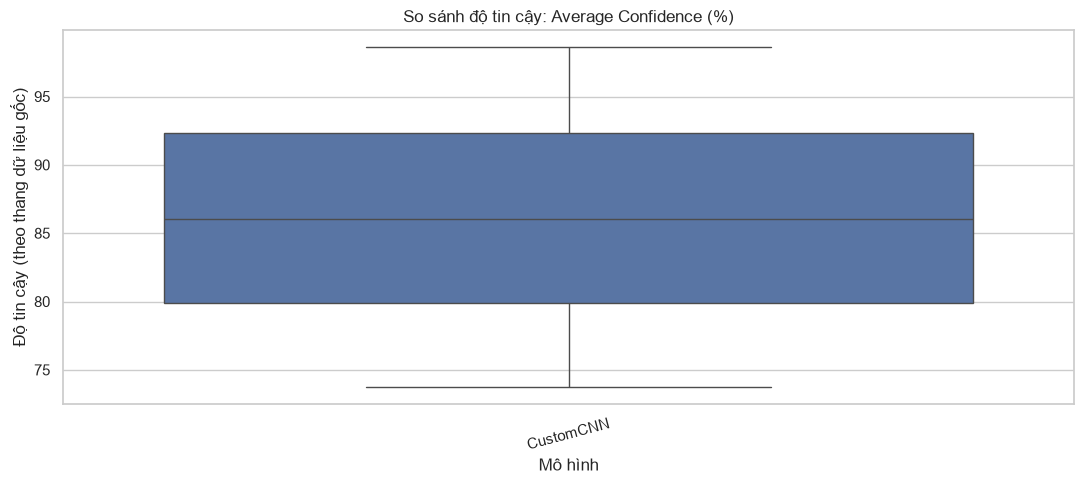

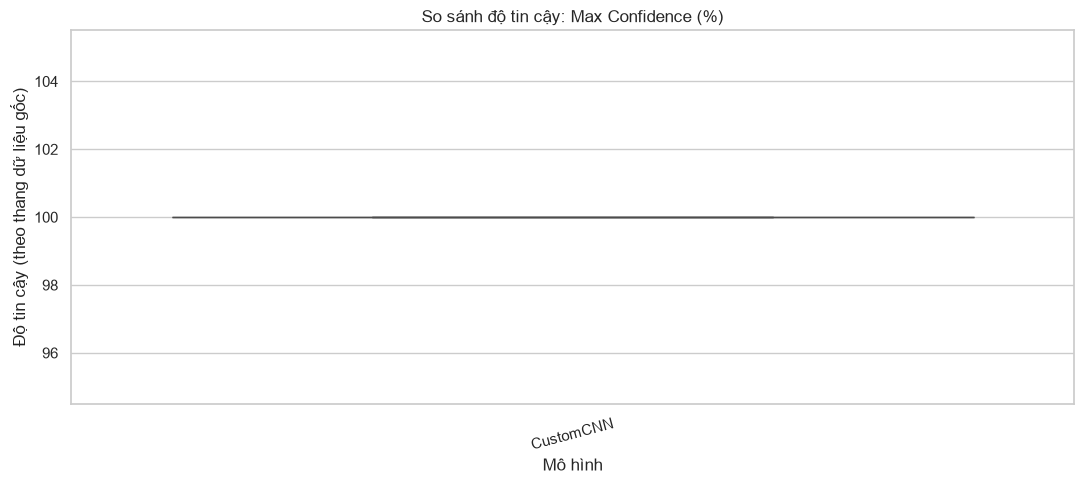

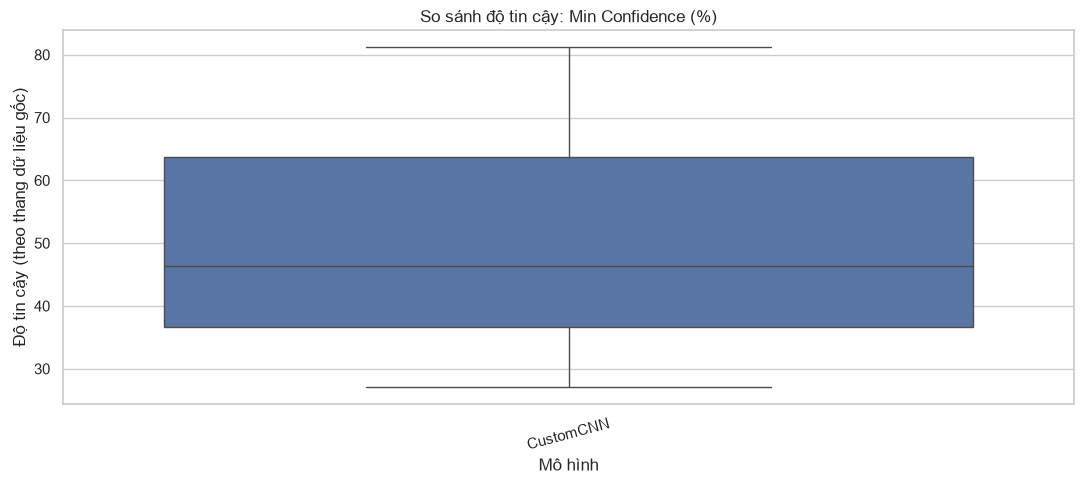

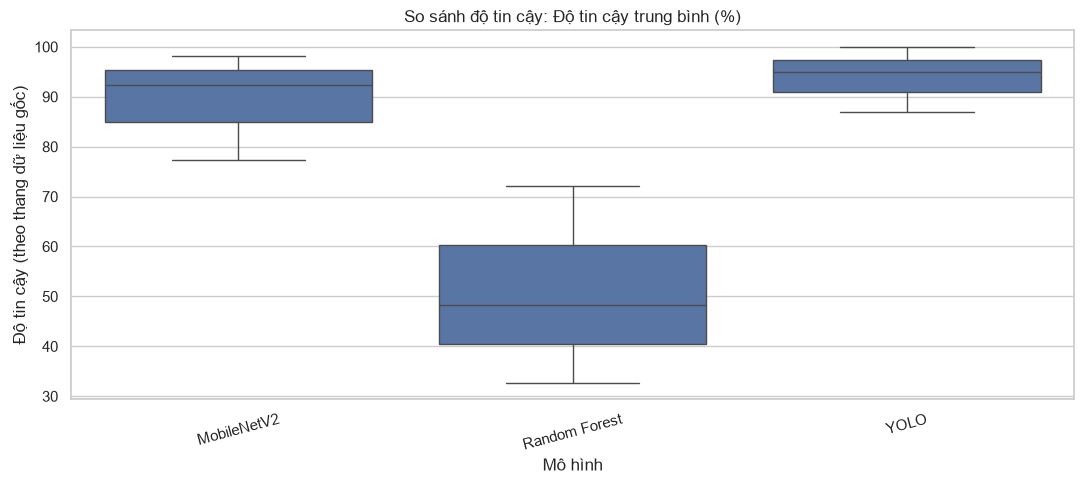

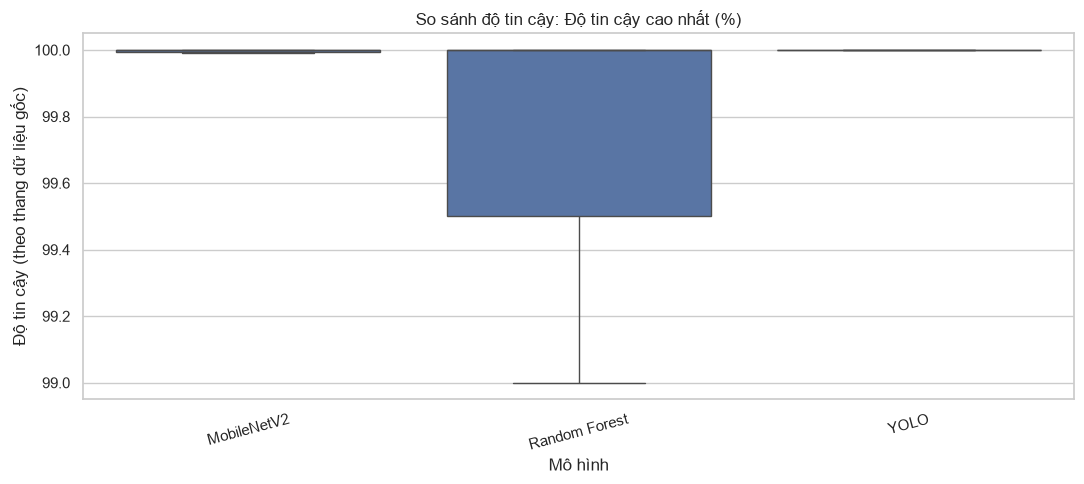

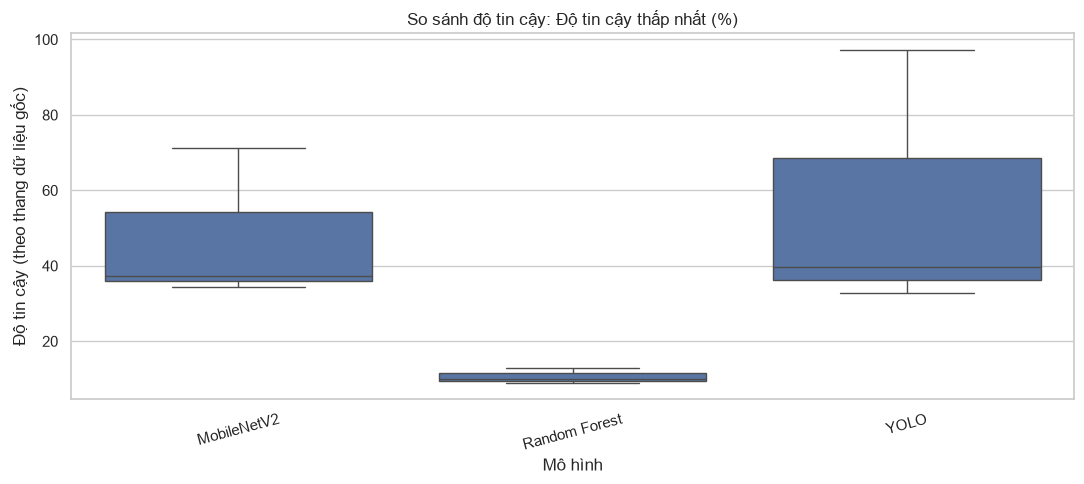

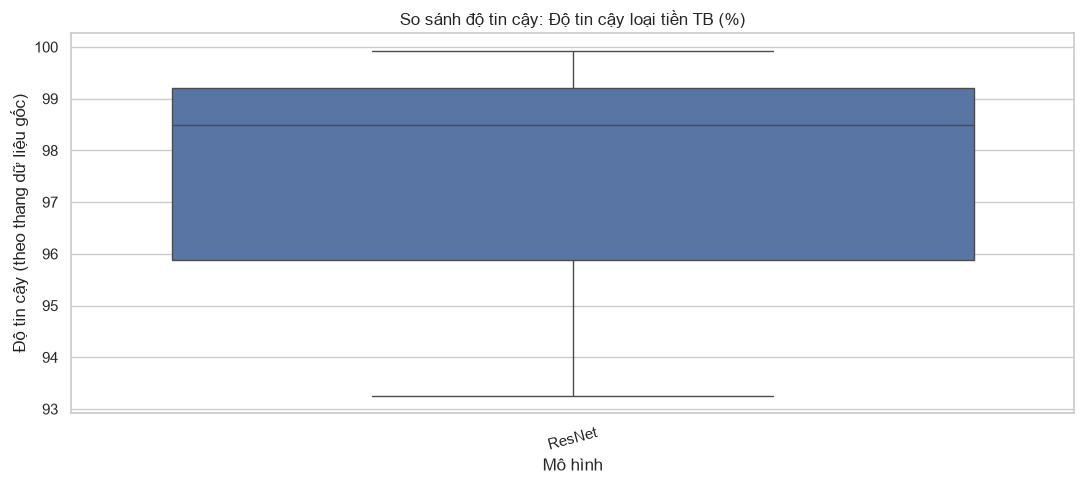

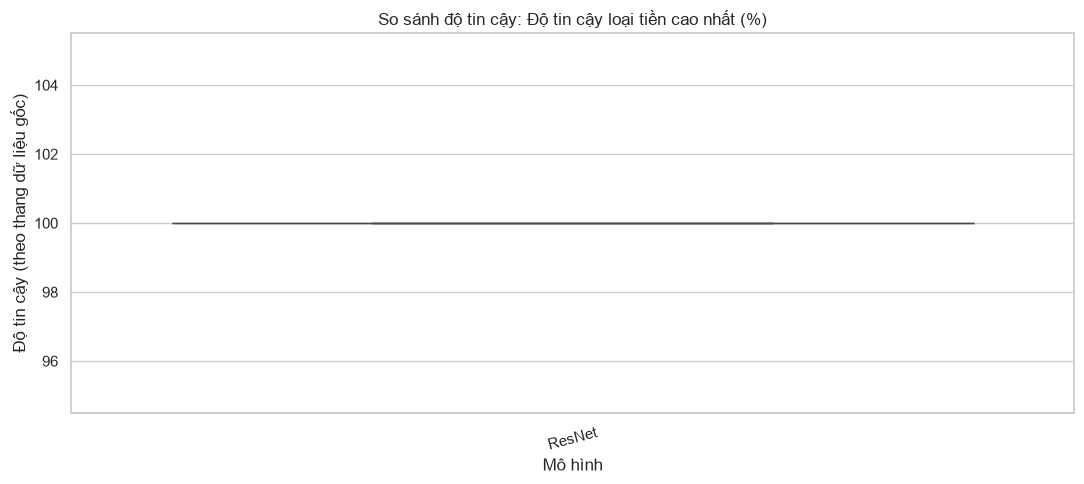

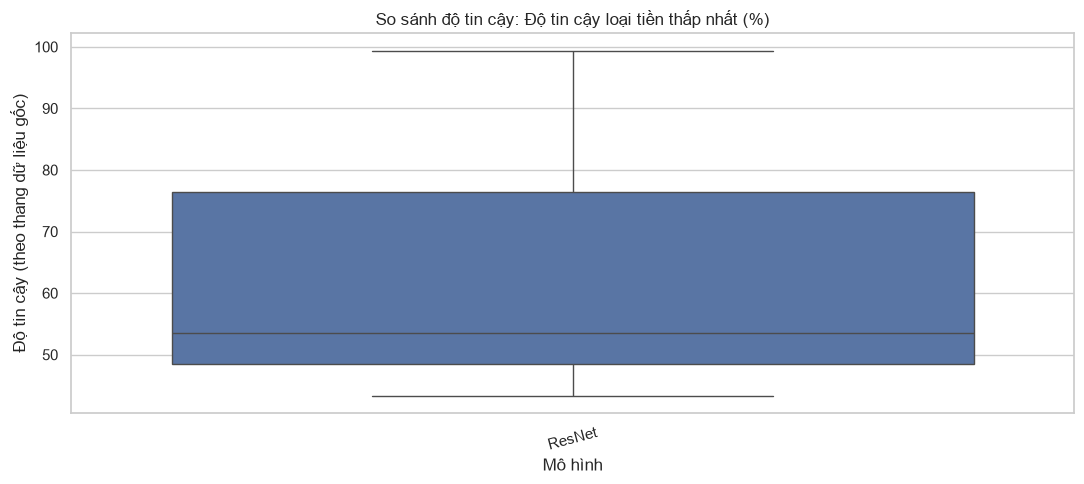

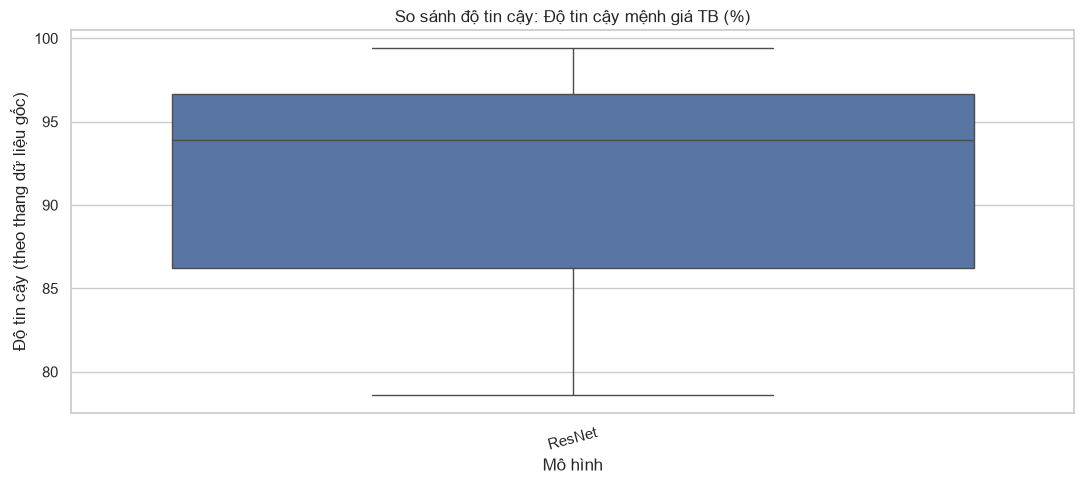

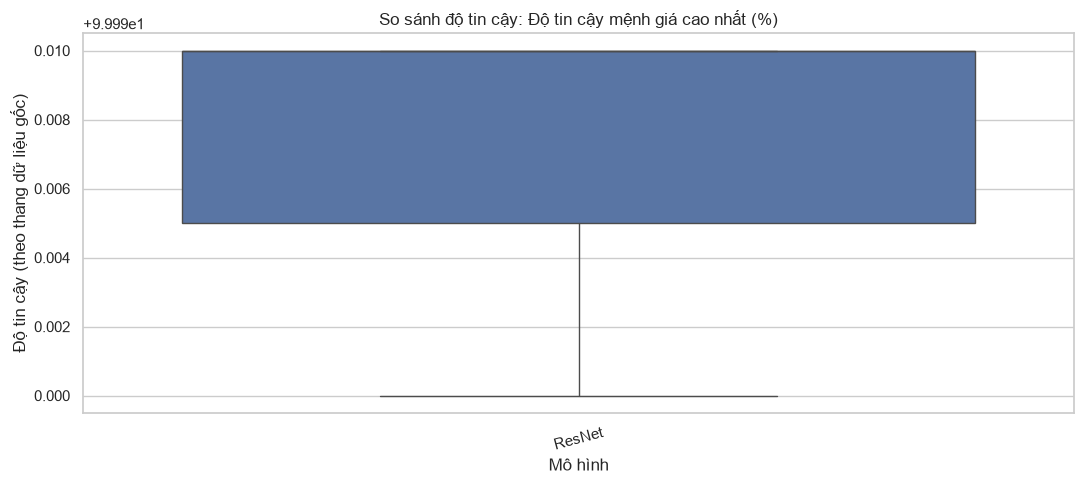

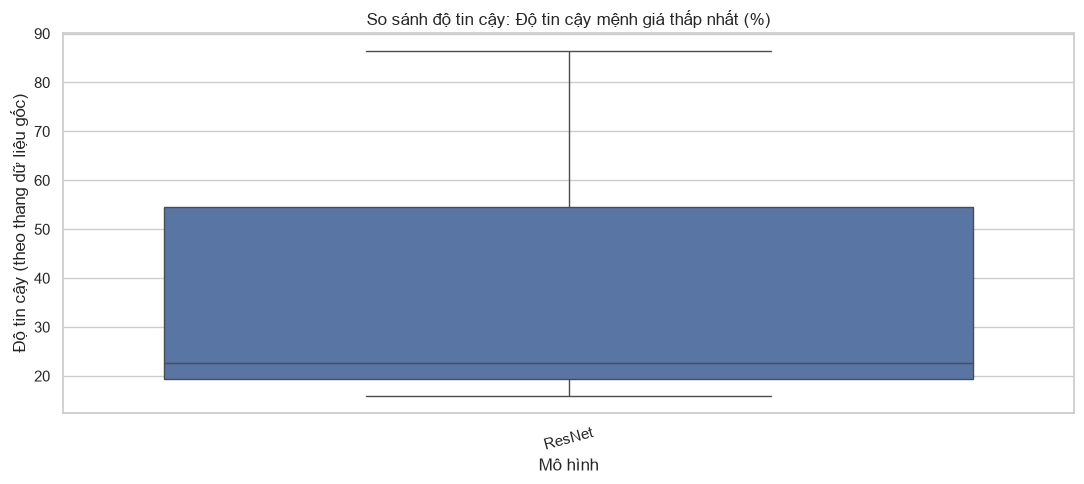

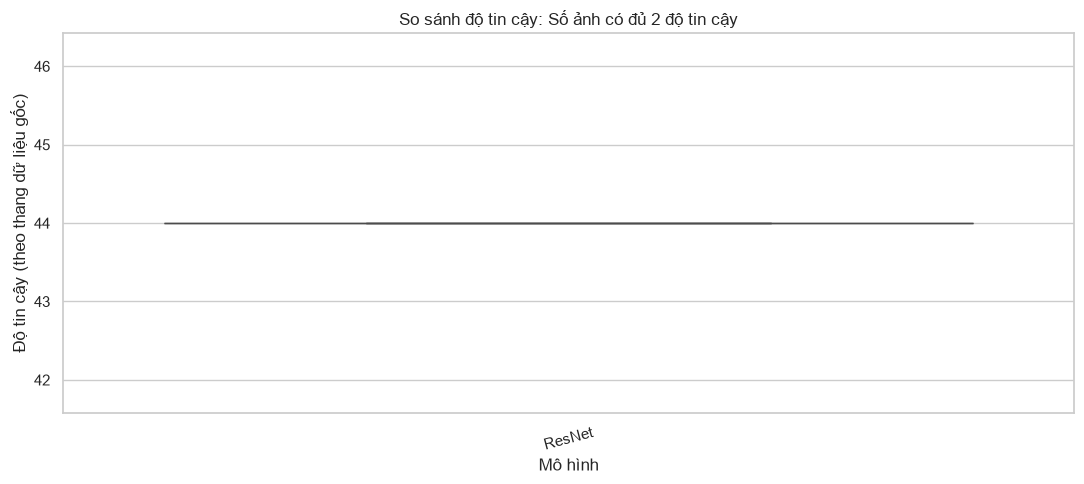

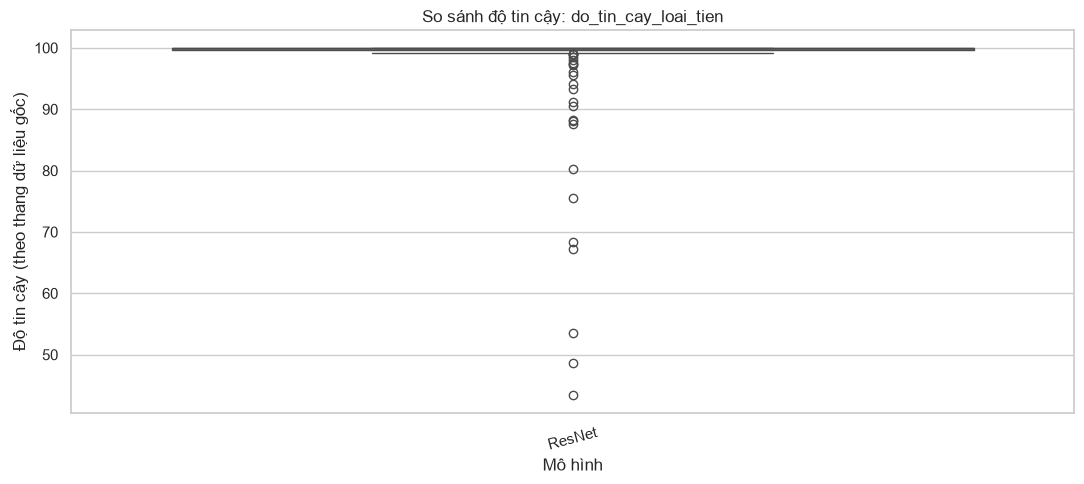

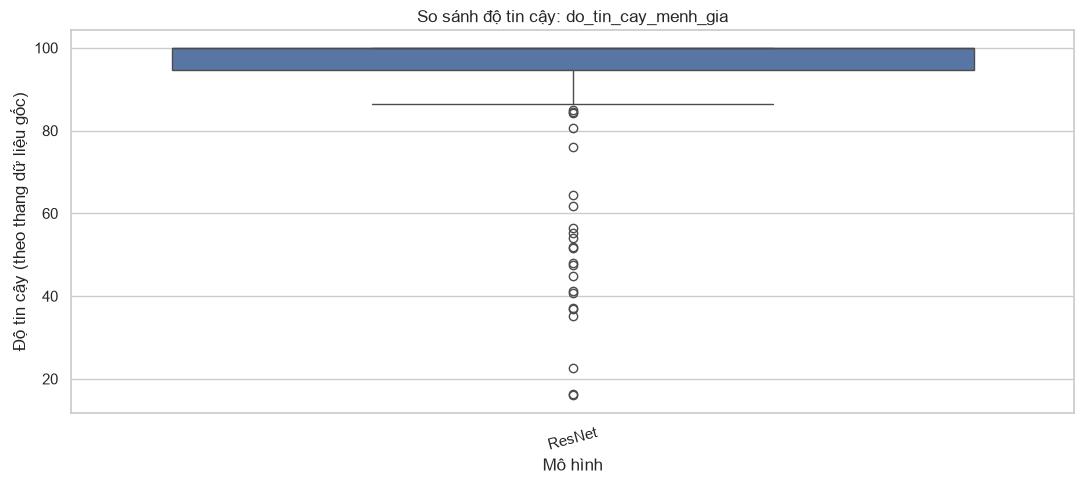

In [9]:
confidence_frames = []

for key, df in csv_data.items():
    model = key.split("/", 1)[0]
    for col in df.columns:
        col_norm = normalize_text(col)
        if any(term in col_norm for term in ["confidence", "tin_cay", "probability"]):
            values = pd.to_numeric(df[col], errors="coerce").dropna()
            if len(values):
                confidence_frames.append(pd.DataFrame({
                    "Mô hình": model,
                    "Trường độ tin cậy": col,
                    "Giá trị": values
                }))

if confidence_frames:
    confidence_df = pd.concat(confidence_frames, ignore_index=True)
    display(confidence_df.groupby(["Mô hình", "Trường độ tin cậy"])["Giá trị"]
            .agg(["count", "mean", "median", "std", "min", "max"]).round(4))

    # Không gộp các trường confidence khác nhau vào một phân phối chung
    for field in confidence_df["Trường độ tin cậy"].unique():
        subset = confidence_df[confidence_df["Trường độ tin cậy"] == field]
        plt.figure(figsize=(11, 5))
        sns.boxplot(data=subset, x="Mô hình", y="Giá trị")
        plt.title(f"So sánh độ tin cậy: {field}")
        plt.xlabel("Mô hình")
        plt.ylabel("Độ tin cậy (theo thang dữ liệu gốc)")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()
else:
    print("Không tìm thấy cột độ tin cậy có thể đọc dạng số.")

## 8. So sánh nhãn loại tiền và mệnh giá

Các file thống kê của từng mô hình có thể có cấu trúc khác nhau. Cell này dò những CSV có cột loại tiền hoặc mệnh giá, sau đó:
- Nếu dữ liệu là từng dự đoán, đếm số bản ghi theo nhãn.
- Nếu CSV đã có cột số lượng, hiển thị bảng nguồn để tránh đếm sai.
- Không cộng gộp các bảng có cấu trúc không tương thích.

,Mô hình,Nhãn,Số lượng
0,Random Forest,CNY,3
1,Random Forest,CNY - 1,2
2,Random Forest,CNY - 10,2
3,Random Forest,CNY - 100,3
4,Random Forest,CNY - 20,3
...,...,...,...
74,YOLO,VND - 20000,3
75,YOLO,VND - 200000,3
76,YOLO,VND - 5000,3
77,YOLO,VND - 50000,3


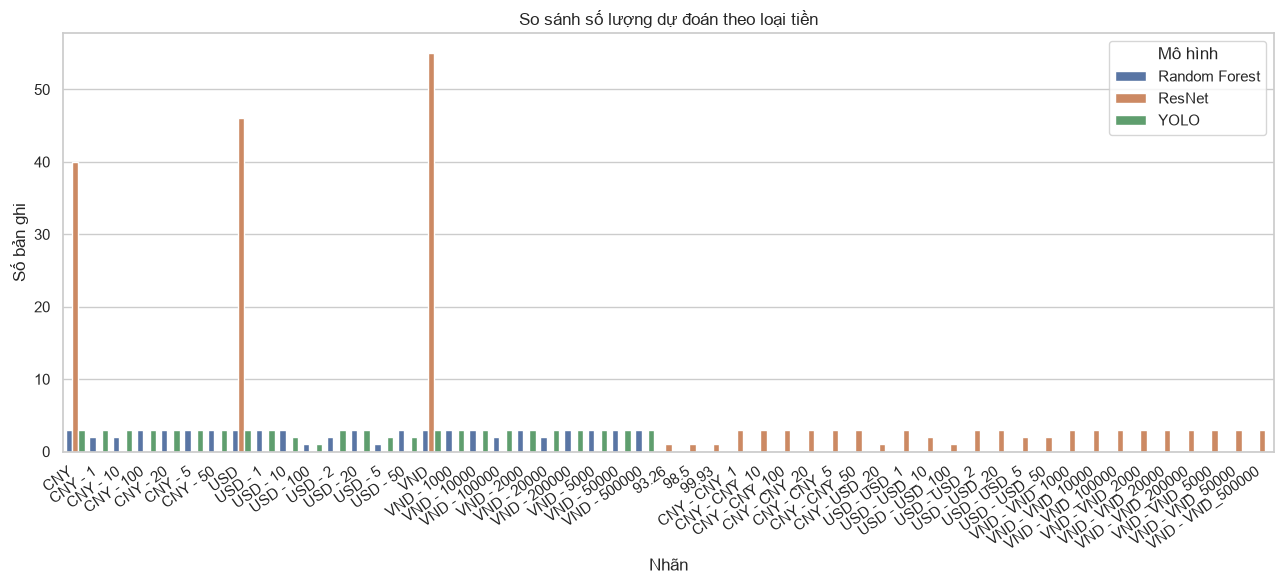

,Mô hình,Nhãn,Số lượng
0,Random Forest,1,3
1,Random Forest,2,2
2,Random Forest,5,3
3,Random Forest,10,3
4,Random Forest,20,3
...,...,...,...
119,YOLO,VND - 20000,3
120,YOLO,VND - 200000,3
121,YOLO,VND - 5000,3
122,YOLO,VND - 50000,3


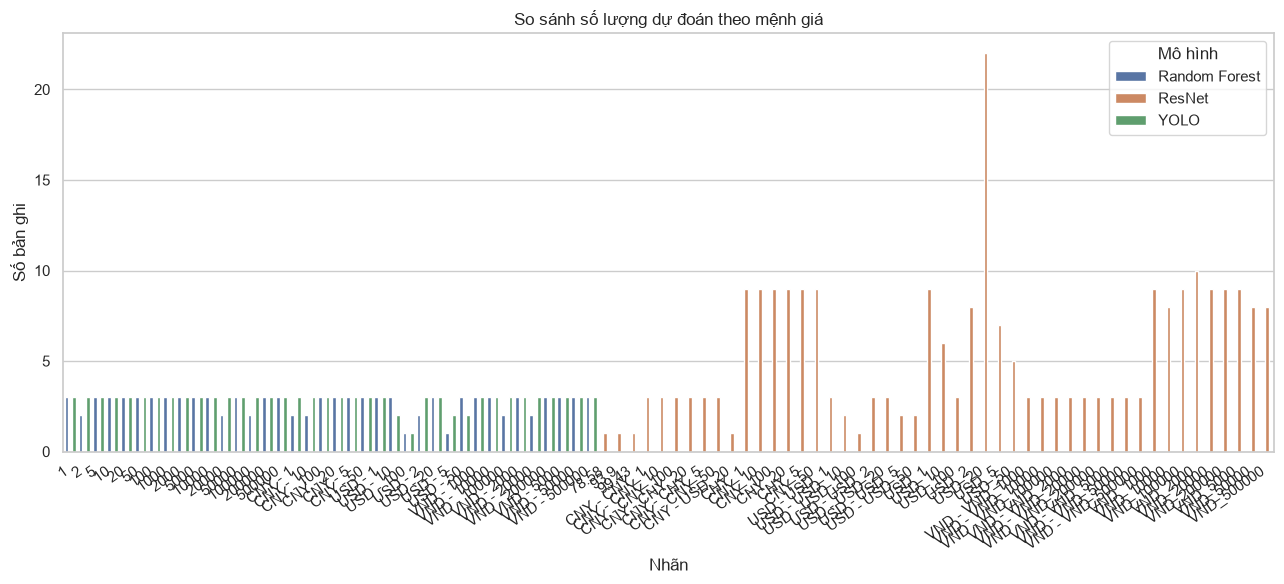

In [10]:
def plot_label_counts(field_name, title):
    frames = []
    for key, df in csv_data.items():
        model = key.split("/", 1)[0]
        col = find_column(df, COLUMN_ALIASES[field_name])
        if col is None:
            continue

        # Chỉ dùng bảng dạng bản ghi nhãn; bỏ qua bảng có cột số lượng rõ ràng
        count_col = next((c for c in df.columns
                          if normalize_text(c) in ["so_luong", "count", "quantity", "tong"]), None)

        if count_col is not None:
            print(f"Bỏ qua tự động đếm {key}: có cột số lượng '{count_col}'. "
                  "Hãy xem bảng CSV gốc để xác định đúng cấu trúc.")
            continue

        temp = df[[col]].dropna().copy()
        temp.columns = ["Nhãn"]
        temp["Mô hình"] = model
        frames.append(temp)

    if not frames:
        print(f"Không tìm thấy dữ liệu dạng bản ghi cho trường {field_name}.")
        return

    combined = pd.concat(frames, ignore_index=True)
    counts = (combined.groupby(["Mô hình", "Nhãn"]).size()
              .reset_index(name="Số lượng"))
    display(counts)

    plt.figure(figsize=(13, 6))
    sns.barplot(data=counts, x="Nhãn", y="Số lượng", hue="Mô hình")
    plt.title(title)
    plt.xlabel("Nhãn")
    plt.ylabel("Số bản ghi")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

plot_label_counts("currency", "So sánh số lượng dự đoán theo loại tiền")
plot_label_counts("denomination", "So sánh số lượng dự đoán theo mệnh giá")

## 9. So sánh trạng thái dự đoán

Tên trạng thái có thể khác nhau giữa các mô hình. Notebook sẽ hiển thị phân bố các giá trị trạng thái tìm được, không tự suy diễn rằng một nhãn bất kỳ là thành công/thất bại nếu chưa xác định quy ước.

In [11]:
status_frames = []

for key, df in csv_data.items():
    model = key.split("/", 1)[0]
    col = find_column(df, COLUMN_ALIASES["status"])
    if col:
        temp = df[[col]].dropna().copy()
        temp.columns = ["Trạng thái"]
        temp["Mô hình"] = model
        status_frames.append(temp)

if status_frames:
    status_df = pd.concat(status_frames, ignore_index=True)
    status_counts = (status_df.groupby(["Mô hình", "Trạng thái"]).size()
                     .reset_index(name="Số lượng"))
    display(status_counts)

    plt.figure(figsize=(12, 5))
    sns.barplot(data=status_counts, x="Mô hình", y="Số lượng", hue="Trạng thái")
    plt.title("So sánh trạng thái dự đoán")
    plt.xlabel("Mô hình")
    plt.ylabel("Số lượng")
    plt.tight_layout()
    plt.show()
else:
    print("Không tìm thấy cột trạng thái dự đoán trong các CSV.")

Không tìm thấy cột trạng thái dự đoán trong các CSV.


## 10. Đánh giá phân loại bằng nhãn thực tế (nếu có)

Độ chính xác phân loại chỉ được tính khi có cả nhãn thực tế và nhãn dự đoán trên cùng tập ảnh. Nếu CSV không có hai trường này, notebook sẽ bỏ qua phần metric thay vì tạo ra số liệu không có căn cứ.

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

metric_rows = []
confusion_data = {}

for key, df in csv_data.items():
    model = key.split("/", 1)[0]
    true_col = find_column(df, COLUMN_ALIASES["true_label"])
    pred_col = find_column(df, COLUMN_ALIASES["pred_label"])

    if true_col is None or pred_col is None:
        continue

    valid = df[[true_col, pred_col]].dropna()
    if valid.empty:
        continue

    y_true = valid[true_col].astype(str)
    y_pred = valid[pred_col].astype(str)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    metric_rows.append({
        "Mô hình": model,
        "File": key.split("/", 1)[1],
        "Số mẫu có nhãn": len(valid),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision weighted": precision,
        "Recall weighted": recall,
        "F1-score weighted": f1
    })

    confusion_data[key] = (y_true, y_pred)

if metric_rows:
    metrics_df = pd.DataFrame(metric_rows)
    display(metrics_df.sort_values("F1-score weighted", ascending=False))

    for key, (y_true, y_pred) in confusion_data.items():
        labels = sorted(set(y_true) | set(y_pred))
        cm = confusion_matrix(y_true, y_pred, labels=labels)
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=labels, yticklabels=labels)
        plt.title(f"Confusion Matrix - {key}")
        plt.xlabel("Nhãn dự đoán")
        plt.ylabel("Nhãn thực tế")
        plt.tight_layout()
        plt.show()
else:
    print(
        "Chưa có cặp cột nhãn thực tế và nhãn dự đoán trong các CSV. "
        "Vì vậy không thể tính Accuracy, Precision, Recall, F1-score hoặc Confusion Matrix."
    )

Chưa có cặp cột nhãn thực tế và nhãn dự đoán trong các CSV. Vì vậy không thể tính Accuracy, Precision, Recall, F1-score hoặc Confusion Matrix.


## 11. Đọc và đối chiếu các báo cáo thống kê TXT

Báo cáo TXT có thể chứa thông tin giải thích hoặc bảng thống kê đã định dạng. Cell này hiển thị toàn bộ nội dung để người thực hiện đối chiếu với các bảng CSV.

In [13]:
for key, content in report_texts.items():
    print("\n" + "=" * 100)
    print("BÁO CÁO:", key)
    print("=" * 100)
    print(content)


BÁO CÁO: CustomCNN/classification_reports.txt
BAO CAO THONG KE KET QUA 3 MO HINH CUSTOM CNN

Lưu ý: File CSV không có nhãn thực tế.
Không thể tính Accuracy, Precision, Recall, F1-score và Confusion Matrix.

========== Model 1 ==========
Tong so anh: 44
So anh xu ly thanh cong: 44
So anh xu ly that bai: 0
Do tin cay trung binh: 98.59%

Thong ke theo nhan du doan:
Nhãn dự đoán
20            2
10 dollar     2
1 dollar      2
2 doolar      2
20 dollar     2
10            2
5             2
5 dollar      2
050000        2
020000        2
50            2
50 dollar     2
1             2
100000        2
200000        2
500000        2
002000        2
010000        2
001000        2
005000        2
100 dollar    2
100           2

========== Model 2 ==========
Tong so anh: 44
So anh xu ly thanh cong: 44
So anh xu ly that bai: 0
Do tin cay trung binh: 86.04%

Thong ke theo nhan du doan:
Nhãn dự đoán
20 dollar    6
010000       4
002000       3
50           3
200000       3
10           2
100    

## 12. Xuất bảng tổng hợp kết quả

Các bảng được xuất vào `ket_qua_thong_ke/So_Sanh_Tong_Hop/` để thuận tiện đưa vào báo cáo. Những bảng không có dữ liệu sẽ không được tạo.

In [14]:
OUTPUT_DIR = RESULT_DIR / "So_Sanh_Tong_Hop"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not structure_df.empty:
    structure_df.to_csv(OUTPUT_DIR / "kiem_tra_cau_truc_du_lieu.csv",
                        index=False, encoding="utf-8-sig")

if not quality_df.empty:
    quality_df.to_csv(OUTPUT_DIR / "kiem_tra_chat_luong_du_lieu.csv",
                      index=False, encoding="utf-8-sig")

if not summary_df.empty:
    summary_df.to_csv(OUTPUT_DIR / "tong_hop_thong_ke_co_ban.csv",
                      index=False, encoding="utf-8-sig")

if "confidence_df" in globals() and not confidence_df.empty:
    confidence_df.to_csv(OUTPUT_DIR / "du_lieu_do_tin_cay_tong_hop.csv",
                         index=False, encoding="utf-8-sig")

if "metrics_df" in globals() and not metrics_df.empty:
    metrics_df.to_csv(OUTPUT_DIR / "cac_chi_so_danh_gia_phan_loai.csv",
                      index=False, encoding="utf-8-sig")

print("Đã lưu các bảng tổng hợp tại:", OUTPUT_DIR.resolve())

Đã lưu các bảng tổng hợp tại: C:\Users\ADmin\Desktop\Python-Final-Project\ket_qua_thong_ke\So_Sanh_Tong_Hop


## 13. Nhận xét và đánh giá kết quả

### 13.1. Nhận xét về dữ liệu

Qua quá trình thống kê, nhóm đã thực hiện so sánh 5 mô hình nhận diện tiền giấy gồm CustomCNN, MobileNetV2, Random Forest, ResNet và YOLO.

Đối với CustomCNN, MobileNetV2, Random Forest và YOLO, mỗi mô hình được kiểm tra trên 3 mô hình thành phần, mỗi mô hình thành phần xử lý 44 ảnh. Như vậy, mỗi nhóm kết quả có tổng cộng 132 lượt xử lý ảnh.

Đối với ResNet, dữ liệu cũng gồm 3 tệp kiểm tra, mỗi tệp có 44 ảnh, tổng cộng 132 ảnh.

Các file CSV và TXT đều được đọc thành công, không phát hiện lỗi đọc dữ liệu. Tuy nhiên, dữ liệu giữa các mô hình có cấu trúc và cách đặt tên nhãn chưa hoàn toàn đồng nhất. Vì vậy, việc so sánh trực tiếp số lượng từng nhãn cần được thực hiện thận trọng.

### 13.2. Nhận xét về độ tin cậy

Dựa trên các báo cáo thống kê, độ tin cậy trung bình của các mô hình có sự khác biệt đáng kể.

| Mô hình | Độ tin cậy trung bình |
|:---|---:|
| CustomCNN | 86,13% |
| MobileNetV2 | 89,33% |
| Random Forest | 51,06% |
| ResNet | Khoảng 93,93%* |
| YOLO | 93,95% |

\*ResNet được tính bằng trung bình các mức confidence loại tiền và mệnh giá của 3 tập kiểm tra; đây là số liệu tổng hợp tham khảo, không phải chỉ số Accuracy.

**Nhận xét:**

- **CustomCNN:** Mô hình 1 đạt độ tin cậy trung bình cao nhất 98,59%, mô hình 2 đạt 86,04% và mô hình 3 đạt 73,76%. Điều này cho thấy độ tin cậy có sự suy giảm giữa các mô hình thành phần.
- **MobileNetV2:** Mô hình 1 đạt 98,21%, mô hình 2 đạt 92,40% và mô hình 3 đạt 77,37%. Kết quả cho thấy mô hình 1 có mức độ tin cậy cao, trong khi mô hình 3 còn hạn chế.
- **Random Forest:** Độ tin cậy giảm từ 72,09% xuống 48,36% và 32,73%. Đây là mô hình có độ tin cậy trung bình thấp nhất trong nhóm được thống kê.
- **ResNet:** Độ tin cậy nhận diện loại tiền ở cả 3 tập kiểm tra khá cao, lần lượt là 99,93%, 98,50% và 93,26%. Tuy nhiên, độ tin cậy nhận diện mệnh giá giảm rõ rệt, từ 99,43% xuống 93,89% và 78,58%.
- **YOLO:** Mô hình 1 đạt 99,92%, mô hình 2 đạt 94,92% và mô hình 3 đạt 87,02%. Đây là kết quả có độ tin cậy cao và tương đối tốt giữa các mô hình thành phần.

Nhìn chung, ResNet và YOLO có mức độ tin cậy trung bình cao nhất trong các kết quả thống kê. Tuy nhiên, độ tin cậy chỉ thể hiện mức độ chắc chắn do mô hình đưa ra, không đồng nghĩa với tỷ lệ dự đoán chính xác.

### 13.3. Nhận xét về loại tiền và mệnh giá

Kết quả thống kê cho thấy các mô hình đều có khả năng đưa ra dự đoán đối với ba nhóm tiền chính:

- **VND:** Tiền Việt Nam đồng.
- **USD:** Đô la Mỹ.
- **CNY:** Nhân dân tệ Trung Quốc.

Đối với ResNet và YOLO, kết quả ở tập kiểm tra thứ nhất có phân bố loại tiền giống nhau: VND có 18 ảnh, USD có 14 ảnh và CNY có 12 ảnh.

Ở các tập kiểm tra tiếp theo, số lượng dự đoán giữa các loại tiền có sự thay đổi. Đặc biệt, tại tập kiểm tra thứ ba của YOLO, mệnh giá USD 20 xuất hiện 14 lần trong thống kê dự đoán, cho thấy mô hình có xu hướng tập trung nhiều vào nhãn này.

Đối với Random Forest, số lượng dự đoán giữa các loại tiền cũng có sự thay đổi giữa ba mô hình thành phần. Điều này cho thấy kết quả phân loại chưa thực sự ổn định.

Ngoài ra, một số nhãn dự đoán có cách viết chưa đồng nhất, ví dụ `20`, `20 dollar`, `AmericanDollar_20 Dollar` hoặc các nhãn mệnh giá có tiền tố khác nhau. Điều này có thể gây khó khăn khi tổng hợp và so sánh dữ liệu.

Do chưa có nhãn thực tế (Ground Truth), nhóm chưa thể xác định chính xác mô hình nào phân loại đúng hoặc sai đối với từng loại tiền và mệnh giá.

### 13.4. Ưu điểm và hạn chế của từng mô hình

**CustomCNN**

- **Ưu điểm:** Có độ tin cậy cao ở mô hình thành phần thứ nhất, đạt 98,59%. Các ảnh kiểm tra đều được xử lý thành công.
- **Hạn chế:** Độ tin cậy giảm đáng kể ở mô hình thành phần thứ ba, còn 73,76%. Kết quả giữa các mô hình thành phần chưa đồng đều.

**MobileNetV2**

- **Ưu điểm:** Đạt độ tin cậy trung bình 89,33%, kết quả của hai mô hình thành phần đầu tương đối cao. Kiến trúc MobileNetV2 có ưu thế về khả năng triển khai trên thiết bị có tài nguyên hạn chế.
- **Hạn chế:** Độ tin cậy ở mô hình thành phần thứ ba chỉ đạt 77,37%, cho thấy khả năng dự đoán chưa ổn định hoàn toàn.

**Random Forest**

- **Ưu điểm:** Có khả năng thống kê và phân loại dữ liệu dựa trên đặc trưng đầu vào. Cả ba mô hình thành phần đều xử lý thành công 44/44 ảnh.
- **Hạn chế:** Độ tin cậy trung bình thấp, lần lượt là 72,09%, 48,36% và 32,73%. Kết quả cho thấy mô hình còn gặp khó khăn trong việc phân biệt các loại tiền và mệnh giá.

**ResNet**

- **Ưu điểm:** Có khả năng trích xuất đặc trưng hình ảnh tốt. Độ tin cậy nhận diện loại tiền đạt mức cao ở cả ba tập kiểm tra, trong đó tập thứ nhất đạt 99,93%.
- **Hạn chế:** Độ tin cậy nhận diện mệnh giá giảm xuống còn 78,58% ở tập kiểm tra thứ ba. Một số dự đoán mệnh giá có sự phân bố không đồng đều.

**YOLO**

- **Ưu điểm:** Có độ tin cậy cao, đặc biệt mô hình thành phần thứ nhất đạt 99,92%. Cả ba mô hình thành phần đều xử lý thành công 44/44 ảnh. YOLO cũng có tiềm năng ứng dụng trong các hệ thống nhận diện hình ảnh cần xử lý nhanh.
- **Hạn chế:** Độ tin cậy giảm từ 99,92% xuống 87,02% giữa các mô hình thành phần. Ở tập thứ ba, một số nhãn mệnh giá có số lượng dự đoán tập trung bất thường.

### 13.5. Kết luận lựa chọn mô hình

Dựa trên kết quả thống kê hiện tại, YOLO và ResNet là hai mô hình có độ tin cậy trung bình nổi bật nhất. YOLO đạt khoảng 93,95%, trong khi ResNet đạt khoảng 93,93% theo cách tổng hợp confidence loại tiền và mệnh giá.

Trong đó, YOLO có ưu điểm là kết quả thống kê confidence cao và cả ba mô hình thành phần đều xử lý thành công toàn bộ ảnh kiểm tra. ResNet có thế mạnh ở khả năng nhận diện loại tiền với độ tin cậy cao, nhưng kết quả nhận diện mệnh giá ở tập kiểm tra thứ ba còn giảm.

Vì vậy, nhóm có thể ưu tiên YOLO và ResNet để tiếp tục thử nghiệm, trong đó YOLO là ứng viên đáng chú ý cho hệ thống nhận diện tiền giấy.

Tuy nhiên, đây mới là kết luận dựa trên độ tin cậy và trạng thái xử lý. Để xác định mô hình thực sự tốt nhất, cần bổ sung nhãn thực tế và đánh giá bằng Accuracy, Precision, Recall, F1-score, đồng thời đo thời gian xử lý trên cùng một tập dữ liệu.

---

## 14. Tổng kết

Thông qua quá trình thực hiện, nhóm đã xây dựng quy trình thống kê, phân tích và so sánh kết quả của năm mô hình nhận diện tiền giấy gồm CustomCNN, MobileNetV2, Random Forest, ResNet và YOLO.

Các mô hình được kiểm tra trên ba tập dữ liệu thành phần, mỗi tập gồm 44 ảnh. Kết quả được tổng hợp thông qua các bảng thống kê, biểu đồ phân bố độ tin cậy, thống kê loại tiền và mệnh giá.

Kết quả thực nghiệm cho thấy YOLO và ResNet có độ tin cậy dự đoán nổi bật hơn so với các mô hình còn lại. MobileNetV2 và CustomCNN cũng đạt kết quả tương đối tốt, trong khi Random Forest có độ tin cậy thấp và chưa ổn định giữa các mô hình thành phần.

Bên cạnh những kết quả đạt được, quá trình thực hiện vẫn còn một số hạn chế:

- Chưa có nhãn thực tế để xác định chính xác tỷ lệ nhận diện đúng và sai.
- Cách đặt tên nhãn giữa các mô hình chưa thống nhất hoàn toàn.
- Độ tin cậy của một số mô hình có sự chênh lệch đáng kể giữa các tập kiểm tra.
- Chưa có số liệu đo thời gian xử lý để đánh giá đầy đủ khả năng triển khai thực tế.

Trong thời gian tới, nhóm có thể cải thiện hệ thống bằng cách chuẩn hóa dữ liệu và nhãn, bổ sung tập kiểm tra có nhãn thực tế, đánh giá bằng các chỉ số phân loại và tối ưu tốc độ xử lý.

**Kết luận chung:** Đề tài đã bước đầu thực hiện được việc so sánh và đánh giá năm mô hình nhận diện tiền giấy thông qua dữ liệu thực nghiệm. Trong phạm vi kết quả hiện có, YOLO và ResNet là hai mô hình có tiềm năng phát triển tiếp. Việc lựa chọn mô hình cuối cùng cần được xác nhận bằng các phép đánh giá chính xác trên tập dữ liệu có nhãn thực tế.

---

**Lưu ý:** Notebook hiện tại chưa có Ground Truth, nên không nên ghi rằng YOLO hoặc ResNet có Accuracy cao nhất hay nhận diện chính xác nhất. Các kết luận ở trên chỉ dựa trên confidence và tỷ lệ xử lý thành công.